In [ ]:
#!/usr/bin/python

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split

url = 'https://raw.githubusercontent.com/coledd/keras-example/master/moon_data.csv'

# Load the training data, format: x, y, label

dataset = pd.read_csv(url, error_bad_lines=False)

In [ ]:
dataset.columns = ['X1', 'X2', 'Y']
dataset.head()
class_names = ['clase_1', 'clase_2']

In [ ]:
dataset.shape

(199, 3)

In [ ]:
data = dataset[['X1', 'X2']].values
labels = dataset['Y'].values

print(data.shape)
print(labels.shape)

(199, 2)
(199,)


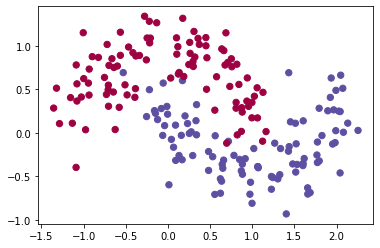

In [ ]:
plt.scatter(data[:,0], data[:,1], s=40, c=labels, cmap=plt.cm.Spectral)
plt.show()

In [ ]:
# Split the data into training and test data
data_train, data_test, labels_train, labels_test = train_test_split(data, labels)


In [ ]:
import keras
from keras.models import Sequential
from keras.layers import Dense, Dropout

# Build the model
model = Sequential()
model.add(Dense(5, activation='linear' , input_shape=(2,), name = "Capa_de_Entrada"))
model.add(Dense(5, activation='relu'   , name = "Capa_de_Oculta"))
model.add(Dense(1, activation='sigmoid', name = "Capa_de_Salida"))


In [ ]:
# Configure a model for mean-squared error regression.
model.compile(loss='mse', optimizer='adam')

In [ ]:
# checkpointer = keras.callbacks.ModelCheckpoint(filepath="weights.h5", verbose=1, save_best_only=True)
model.summary()

Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
Capa_de_Entrada (Dense)      (None, 5)                 15        
_________________________________________________________________
Capa_de_Oculta (Dense)       (None, 5)                 30        
_________________________________________________________________
Capa_de_Salida (Dense)       (None, 1)                 6         
Total params: 51
Trainable params: 51
Non-trainable params: 0
_________________________________________________________________


Epoch 1/1000
4/4 [==============================] - 1s 143ms/step - loss: 0.3172 - val_loss: 0.2827
Epoch 2/1000
4/4 [==============================] - 0s 14ms/step - loss: 0.3258 - val_loss: 0.2787
Epoch 3/1000
4/4 [==============================] - 0s 13ms/step - loss: 0.3201 - val_loss: 0.2747
Epoch 4/1000
4/4 [==============================] - 0s 13ms/step - loss: 0.3326 - val_loss: 0.2707
Epoch 5/1000
4/4 [==============================] - 0s 13ms/step - loss: 0.3214 - val_loss: 0.2669
Epoch 6/1000
4/4 [==============================] - 0s 14ms/step - loss: 0.3059 - val_loss: 0.2631
Epoch 7/1000
4/4 [==============================] - 0s 14ms/step - loss: 0.3113 - val_loss: 0.2593
Epoch 8/1000
4/4 [==============================] - 0s 14ms/step - loss: 0.3001 - val_loss: 0.2556
Epoch 9/1000
4/4 [==============================] - 0s 14ms/step - loss: 0.2843 - val_loss: 0.2520
Epoch 10/1000
4/4 [==============================] - 0s 14ms/step - loss: 0.2996 - val_loss: 0.2484
Epoch 11

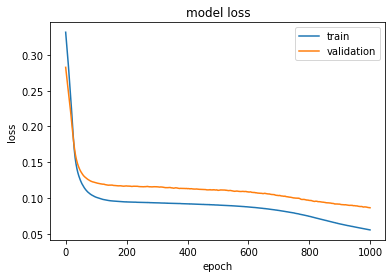

In [ ]:
# Train the model
history = model.fit(data_train, labels_train, epochs=1000, batch_size=32, verbose=1, validation_split=0.2)
model.summary()
print(history.history.keys())
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper right')
plt.show()

In [ ]:
# Evaluar
print(model.evaluate(data, labels))
print(model.metrics_names)

7/7 [==============================] - 0s 2ms/step - loss: 0.0611
0.06112232059240341
['loss']


In [ ]:
def plot_image(i, predictions_array, true_label, data, data_test):
  predictions_array, true_label, data, data_test = predictions_array, true_label[i], data, data_test[i] 
  plt.grid(False)
  plt.xticks([])
  plt.yticks([])

  plt.scatter(data[:,0], data[:,1], s=40, c=labels, cmap=plt.cm.Spectral)
  plt.scatter(data_test[0],data_test[1],s=[100],color='black', marker='*') 

  predicted_label = np.argmax(predictions_array)
  if predicted_label == true_label:
    color = 'red'
  else:
    color = 'blue'

  plt.xlabel("{} {:2.0f}% ({})".format(class_names[predicted_label],
                                100*np.max(predictions_array),
                                class_names[true_label]),
                                color=color)

def plot_value_array(i, predictions_array, true_label):
  predictions_array, true_label = predictions_array, true_label[i]
  plt.grid(False)
  plt.xticks(range(2))
  plt.yticks([])
  thisplot = plt.bar(['predicho = '+np.array_str(predictions_array), 'real = '+str(true_label)], [predictions_array, true_label], color="#777777")
  plt.ylim([0, 1])
  predicted_label = np.argmax(predictions_array)

  thisplot[predicted_label].set_color('#2f3e3f')
  thisplot[true_label].set_color('#2f3e3f')

/usr/local/lib/python3.7/dist-packages/numpy/lib/stride_tricks.py:256: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray
  args = [np.array(_m, copy=False, subok=subok) for _m in args]


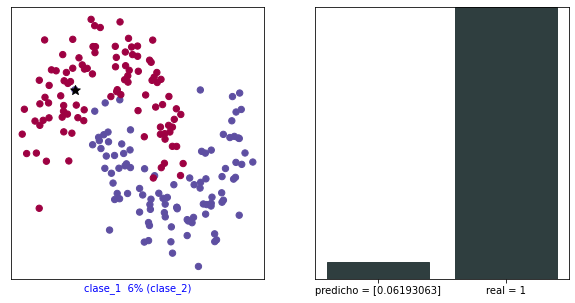

In [ ]:
predictions = model.predict(data_test)

i = 17
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plot_image(i, predictions[i], labels_test, data, data_test)
plt.subplot(1,2,2)
plot_value_array(i, predictions[i],  labels_test)
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report  

predict_label = predictions.reshape(-1).round()

print('Cantidad de predicciones = {} \n'.format(predict_label.shape))

cf_matrix = confusion_matrix(labels_test, predict_label)
print(cf_matrix)

Cantidad de predicciones = (50,) 

[[22  2]
 [ 2 24]]


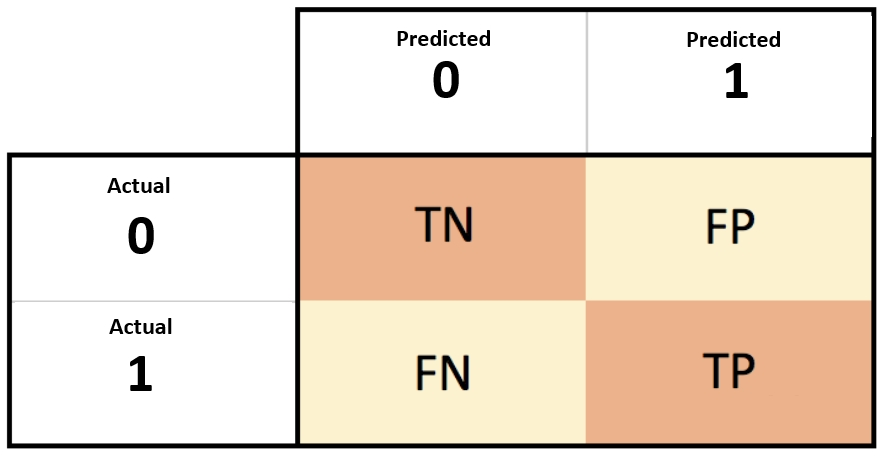

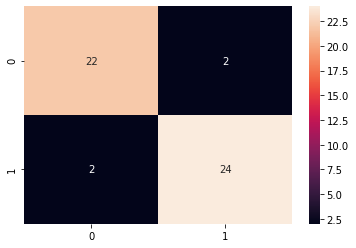

In [ ]:
import seaborn as sns
sns.heatmap(cf_matrix, annot=True)

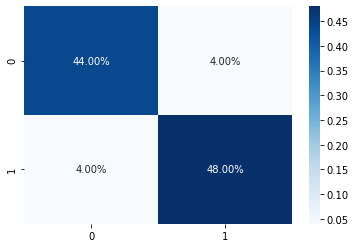

In [ ]:
sns.heatmap(cf_matrix/np.sum(cf_matrix), annot=True, 
            fmt='.2%', cmap='Blues')

In [ ]:
report = classification_report(labels_test, predict_label)  
print(report)

              precision    recall  f1-score   support

           0       0.92      0.92      0.92        24
           1       0.92      0.92      0.92        26

    accuracy                           0.92        50
   macro avg       0.92      0.92      0.92        50
weighted avg       0.92      0.92      0.92        50



**Referencias**

*   https://enmilocalfunciona.io/deep-learning-basico-con-keras-parte-1/
*   https://github.com/coledd/keras-example
*   https://medium.com/@dtuk81/confusion-matrix-visualization-fc31e3f30fea

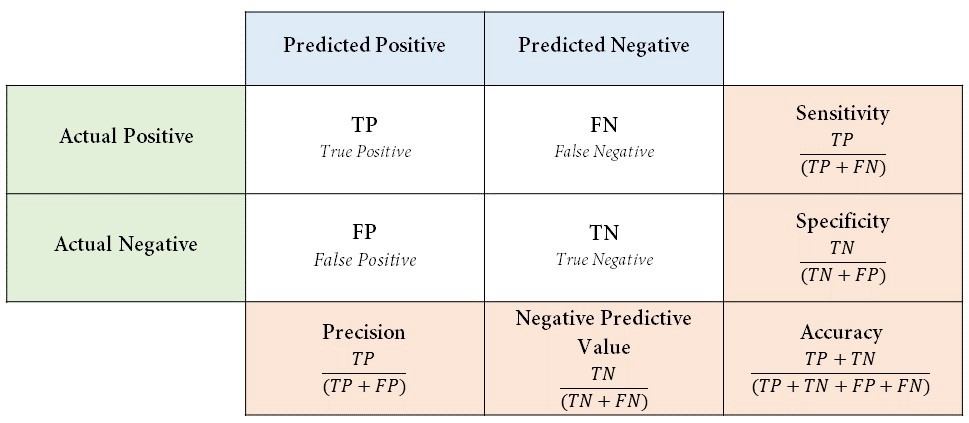